In [ ]:
# Import required libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D , Input , concatenate
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import cifar10
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorflow.keras.optimizers import Adam
import seaborn as sns
from tensorflow.keras import layers, models, optimizers

In [ ]:
(x_train,y_train),(x_test,y_test)=cifar10.load_data()

In [ ]:
x_train.shape

(50000, 32, 32, 3)

In [ ]:
y_train.shape

(50000, 1)

In [ ]:
y_test.shape

(10000, 1)

In [ ]:
x_test.shape

(10000, 32, 32, 3)

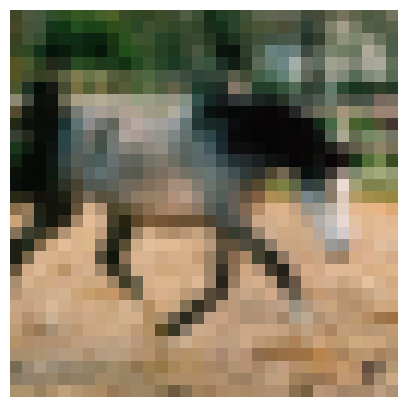

In [ ]:
plt.figure(figsize=(5, 6))
plt.imshow(x_train[52])
plt.axis('off')

plt.show()


In [ ]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train[...,tf.newaxis]
x_test = x_test[...,tf.newaxis]

print('training images shape after adding dimention:',x_train.shape)
print('testing images shape after adding dimention:',x_test.shape)

training images shape after adding dimention: (50000, 32, 32, 3, 1)
testing images shape after adding dimention: (10000, 32, 32, 3, 1)


In [ ]:
from tensorflow.keras import layers, Sequential, Model
from tensorflow.keras.layers import Input, Flatten, Dense, Concatenate

num_classes = 10

# Define an Inception block
def inception_block(x, filters):
    # Branch 1: 1x1 Convolution
    branch1 = layers.Conv2D(filters=filters, kernel_size=1, activation='relu', padding='same')(x)

    # Branch 2: 1x1 Convolution followed by 3x3 Convolution
    branch2 = layers.Conv2D(filters=filters, kernel_size=1, activation='relu', padding='same')(x)
    branch2 = layers.Conv2D(filters=filters, kernel_size=3, activation='relu', padding='same')(branch2)

    # Branch 3: 1x1 Convolution followed by 5x5 Convolution
    branch3 = layers.Conv2D(filters=filters, kernel_size=1, activation='relu', padding='same')(x)
    branch3 = layers.Conv2D(filters=filters, kernel_size=5, activation='relu', padding='same')(branch3)

    # Branch 4: MaxPooling followed by 1x1 Convolution
    branch4 = layers.MaxPooling2D(pool_size=3, strides=1, padding='same')(x)
    branch4 = layers.Conv2D(filters=filters, kernel_size=1, activation='relu', padding='same')(branch4)

    # Concatenate all branches
    output = Concatenate()([branch1, branch2, branch3, branch4])
    return output

# Input layer
input_layer = Input(shape=(32, 32, 3))

# Apply Inception blocks
x = inception_block(input_layer, filters=8)
x = layers.MaxPooling2D(pool_size=2, strides=1)(x)

x = inception_block(x, filters=16)
x = layers.MaxPooling2D(pool_size=2, strides=1)(x)

x = inception_block(x, filters=32)
x = layers.MaxPooling2D(pool_size=2, strides=1)(x)

# Flatten and Fully Connected Layers
x = Flatten()(x)
x = Dense(120, activation='relu')(x)
x = Dense(80, activation='relu')(x)
output_layer = Dense(num_classes, activation='softmax')(x)

# Build the model
model = Model(inputs=input_layer, outputs=output_layer)

# Summary
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1             │ (None, 32, 32, 3)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_15 (Conv2D)        │ (None, 32, 32, 8)      │             32 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_17 (Conv2D)        │ (None, 32, 32, 8)      │             32 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_12          │ (None, 32, 32, 3)      │              0 │ input_layer_1[0][0]    │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_14 (Conv2D)        │ (None, 32, 32, 8)      │             32 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_16 (Conv2D)        │ (None, 32, 32, 8)      │            584 │ conv2d_15[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_18 (Conv2D)        │ (None, 32, 32, 8)      │          1,608 │ conv2d_17[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_19 (Conv2D)        │ (None, 32, 32, 8)      │             32 │ max_pooling2d_12[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 32, 32, 32)     │              0 │ conv2d_14[0][0],       │
│                           │                        │                │ conv2d_16[0][0],       │
│                           │                        │                │ conv2d_18[0][0],       │
│                           │                        │                │ conv2d_19[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_13          │ (None, 31, 31, 32)     │              0 │ concatenate[0][0]      │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_21 (Conv2D)        │ (None, 31, 31, 16)     │            528 │ max_pooling2d_13[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_23 (Conv2D)        │ (None, 31, 31, 16)     │            528 │ max_pooling2d_13[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_14          │ (None, 31, 31, 32)     │              0 │ max_pooling2d_13[0][0] │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_20 (Conv2D)        │ (None, 31, 31, 16)     │            528 │ max_pooling2d_13[0][0] │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_22 (Conv2D)        │ (None, 31, 31, 16)     │          2,320 │ conv2d_21[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_24 (Conv2D)        │ (None, 31, 31, 16)     │          6,416 │ conv2d_23[0][0]        │
├──────────────────────

 Total params: 12,984,738 (49.53 MB)

 Trainable params: 12,984,738 (49.53 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:

history = model.fit(x_train, y_train,epochs=3, batch_size=64,validation_data=(x_test, y_test))


Epoch 1/3


ValueError: Arguments `target` and `output` must have the same shape. Received: target.shape=(None, 1), output.shape=(None, 10)

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

In [ ]:


# Plot training and validation accuracy/loss
def plot_history(history):
    plt.figure(figsize=(12, 4))

    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_history(history)

In [ ]:

# Make predictions on the test set
predictions = model.predict(x_test)
predicted_classes = np.argmax(predictions, axis=1)

# Visualize predictions
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])  # Original image (preprocessed earlier during model training)
    plt.title(f"True: {class_names[np.argmax(y_test[i])]} \nPred: {class_names[predicted_classes[i]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#vgg model
from tensorflow.keras import layers, Sequential, Model
from tensorflow.keras.layers import Input, Flatten, Dense

num_classes = 10

# Define VGG16 model
input_layer = Input(shape=(32, 32, 3))

# Block 1: Convolutional Layers + MaxPooling
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(input_layer)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Block 2: Convolutional Layers + MaxPooling
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Block 3: Convolutional Layers + MaxPooling
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Block 4: Convolutional Layers + MaxPooling
x = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(x)
x = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Block 5: Convolutional Layers + MaxPooling
x = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(x)
x = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D(pool_size=(2, 2))(x)

# Flatten and Fully Connected Layers
x = Flatten()(x)
x = Dense(4096, activation='relu')(x)
x = Dense(4096, activation='relu')(x)
x = Dense(80, activation='relu')(x)
output_layer = Dense(num_classes, activation='softmax')(x)

# Build the model
model = Model(inputs=input_layer, outputs=output_layer)

# Summary of the model
model.summary()
